# Project 1 · Quantum Material Properties

The properties of a material, such as the band gap and the formation energy, determine its chemical and electrical behavior, but are difficult to predict from first principles.

In this project, we learn to predict these properties from chemical structure and composition. <br>
In addition, we learn to select features of importance and to produce uncertainty estimates as well as value estimates.

### Data
Data come from the Materials Project ([link](https://next-gen.materialsproject.org/)). In its raw format, it includes the full crystal structure.  Such data is difficult to analyze because of its complex geometrical nature.<br>
A user can request an API key and download the data and use well-established tools ([matminer](https://hackingmaterials.lbl.gov/matminer/) to produce summary statistics as a fixed-length vector of numbers.

We will use a subset of the data, about 5000 materials which are stable and have <=2 elements.

### Goals
- Visualize the features and the target, understand the nature of the data
- Train a linear regressor to regress the band gap from the vector of features
- Train a neural network to regress the band gap from the vector of features
- Use feature selection algorithms to select the N most important features
- Train a smaller network using only the N most important features
- Compare the performance of the full and subset networks as N varies
- Train M networks, each with its own random seed, to prepare an ensemble of networks; use the mean as the estimate and the variance as uncertainty; study the relationship between the estimated uncertainty and the residual

## What are we predicting from the data?

In this dataset, the primary target variable *y* represents the band gap of each material, measured in electron-volts $\text{ eV}$. <br>
The target variable range (0-18) reflects how much energy is required for electrons to jump from the valence band to the conduction band:<br>

- $0\text{ eV}$ (Metals / Conductors): A band gap of $0\text{ eV}$ means there is no energy barrier separating the valence and conduction bands (or they overlap). Electrons move freely, giving the material high electrical conductivity.
- $0\text{ eV} < y \le 4\text{ eV}$ (Semiconductors): Small-to-moderate band gaps (such as Silicon at $\approx 1.1\text{ eV}$) allow electrons to cross into the conduction band when excited by heat or light. These materials are fundamental to electronics and photovoltaics.
- $4\text{ eV} < y$ (Insulators): Wide band gaps (such as oxides, nitrides, or halides like LiF) require very high energy to excite an electron. These materials block electrical current under normal operating conditions.

## Settings

Choose the data file here.

In [1]:
# The 5000 materials subset
FEATURE_CACHE = "data/features_1or2_stable.pkl"

## Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# should be
# NumPy: 1.26.4
# Pandas: 2.3.3
# scikit-learn: 1.7.2
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

NumPy: 2.2.6
Pandas: 2.3.3
scikit-learn: 1.7.2


In [3]:
# Import torch, check for GPU
import torch
# import torch.nn as nn
# import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
print("Torch v:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Torch v: 2.13.0
CUDA available: False


In [4]:
from src.data import load_data, split_and_scale
from src.train import record_metrics, train_network
from src.plots import plot_corr_mat, plot_val_loss, plot_comparative_loss_curves

## Load and inspect the data

In [5]:
X, y, Xdf = load_data(FEATURE_CACHE)
print(f'\nX type:{type(X)},\nX.shape:{X.shape}\n')
print(f'y type:{type(y)},\ny.shape:{y.shape}\n')
print(f'Xdf type:{type(Xdf)},\nXdf.shape:{Xdf.shape}\n')

Loaded 5,141 samples with 263 features

X type:<class 'numpy.ndarray'>,
X.shape:(5141, 263)

y type:<class 'numpy.ndarray'>,
y.shape:(5141,)

Xdf type:<class 'pandas.core.frame.DataFrame'>,
Xdf.shape:(5141, 263)



`load_data` returns two numpy arrays and one pandas dataframe of the same shape as X.<br>
Let's inspect the dataframe and y band gaps

In [6]:
n=10
Xdf.head(n)

,0-norm,2-norm,3-norm,5-norm,7-norm,10-norm,MagpieData minimum Number,MagpieData maximum Number,MagpieData range Number,MagpieData mean Number,...,mean wt CN_20,std wt CN_20,mean wt CN_21,std wt CN_21,mean wt CN_22,std wt CN_22,mean wt CN_23,std wt CN_23,mean wt CN_24,std wt CN_24
0,1,1.000000,1.000000,1.000000,1.000000,1.000000,89.0,89.0,0.0,89.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,0.721110,0.654213,0.615030,0.604895,0.601032,8.0,89.0,81.0,40.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,0.721110,0.654213,0.615030,0.604895,0.601032,16.0,89.0,73.0,45.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2,0.790569,0.759147,0.750616,0.750049,0.750001,49.0,89.0,40.0,79.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2,0.790569,0.759147,0.750616,0.750049,0.750001,81.0,89.0,8.0,87.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2,0.707107,0.629961,0.574349,0.552045,0.535887,47.0,89.0,42.0,68.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2,0.790569,0.759147,0.750616,0.750049,0.750001,47.0,89.0,42.0,57.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2,0.790569,0.759147,0.750616,0.750049,0.750001,13.0,89.0,76.0,32.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2,0.790569,0.759147,0.750616,0.750049,0.750001,79.0,89.0,10.0,81.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2,0.790569,0.759147,0.750616,0.750049,0.750001,35.0,89.0,54.0,48.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
print(f"First {n} y Band gaps: {y[:n]}")

First 10 y Band gaps: [0.     3.5226 2.2962 0.     0.     0.     0.     0.     0.     4.1033]


In [8]:
Xdf.tail(n)

,0-norm,2-norm,3-norm,5-norm,7-norm,10-norm,MagpieData minimum Number,MagpieData maximum Number,MagpieData range Number,MagpieData mean Number,...,mean wt CN_20,std wt CN_20,mean wt CN_21,std wt CN_21,mean wt CN_22,std wt CN_22,mean wt CN_23,std wt CN_23,mean wt CN_24,std wt CN_24
5131,2,0.745356,0.693361,0.670782,0.667408,0.666732,14.0,40.0,26.0,22.666667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5132,2,0.745356,0.693361,0.670782,0.667408,0.666732,40.0,50.0,10.0,46.666667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5133,2,0.745356,0.693361,0.670782,0.667408,0.666732,40.0,43.0,3.0,42.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5134,2,0.707107,0.629961,0.574349,0.552045,0.535887,40.0,52.0,12.0,46.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5135,2,0.745356,0.693361,0.670782,0.667408,0.666732,40.0,52.0,12.0,48.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5136,2,0.849837,0.835550,0.833387,0.833335,0.833333,40.0,52.0,12.0,50.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5137,2,0.745356,0.693361,0.670782,0.667408,0.666732,40.0,74.0,34.0,62.666667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5138,2,0.707107,0.629961,0.574349,0.552045,0.535887,30.0,40.0,10.0,35.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5139,2,0.745356,0.693361,0.670782,0.667408,0.666732,30.0,40.0,10.0,33.333333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5140,2,0.790569,0.759147,0.750616,0.750049,0.750001,30.0,40.0,10.0,32.500000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
print(f"Last {n} y Band gaps: {y[-n:]}")

Last 10 y Band gaps: [0.     0.     0.     0.     0.     0.0192 0.     0.     0.     0.    ]


There appears to be many 'NaN' values for several features in Xdf. <br>
I'll find which features have 'NaN' values and how many there are per feature

In [10]:
# find how many values per feature are NaN
# drop the features that have no NaN
Xna = Xdf.isna().sum()
Xna = Xna[Xna > 0]
print(f"{len(Xna)} features have NaN values")

137 features have NaN values


In [11]:
# How many features have all NaN?
print(f'{(Xna.values == Xdf.shape[0]).sum()} features have all "NaN"')

122 features have all "NaN"


In [12]:
print(f'{(Xna.values < Xdf.shape[0]).sum()} features have some "NaN"')

15 features have some "NaN"


## Data cleaning

Above I see that 122 columns / features are missing all values for that feature and 15 columns are missing some feature values<br>
Below I create a new dataframe with the columns / features with all 'NaN' dropped and I drop the rows with 'NaN' values to create a clean dataframe.

In [13]:
# Drop features that are entirely NaN (122 columns)
all_nan_cols = Xdf.columns[Xdf.isna().all()]
Xdf_clean = Xdf.drop(columns=all_nan_cols)
print(f"New clean df shape with dropped NaN features: {Xdf_clean.shape}")

New clean df shape with dropped NaN features: (5141, 141)


In [14]:
# Create a boolean mask for rows with NO missing values
val_rows_mask = ~Xdf_clean.isna().any(axis=1)

In [15]:
# 3. Filter both Xdf and y using the mask
Xdf_clean = Xdf_clean[val_rows_mask]
y_clean = y[val_rows_mask]

In [16]:
# Verify matching shapes (both should now have 5,131 samples)
print("Xdf_clean shape:", Xdf_clean.shape)
print("y_clean shape:  ", y_clean.shape)

Xdf_clean shape: (5131, 141)
y_clean shape:   (5131,)


After dropping the features with all 'NaN' values and the rows with some 'NaN' values, our clean dataframe now has values for every column / feature for every sample / row.<br>
There is still a significant amount of data, 5131 samples and 141 features per sample.

## Visualize features and targets, understand the nature of the data

### Target (band gap) distribution check

In [17]:
target_min = min(np.unique(y_clean))
target_max = max(np.unique(y_clean))
print(f"Target ranges from {target_min} to {target_max}")

Target ranges from 0.0 to 9.71969985961914


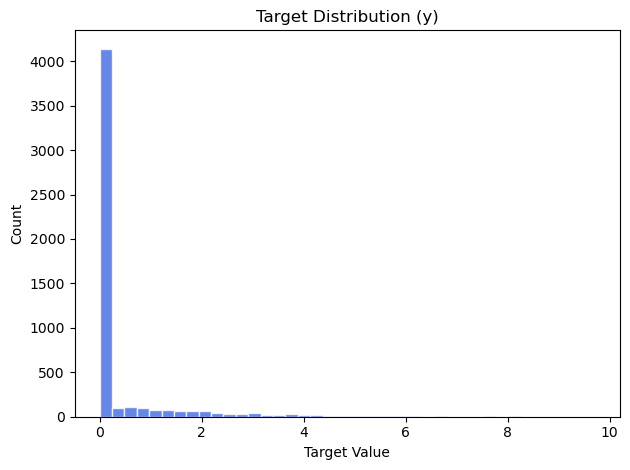

In [18]:
fig, ax = plt.subplots()

# Histogram / KDE
ax.hist(y_clean, bins=40, color='royalblue', edgecolor='white', alpha=0.8)
ax.set_title("Target Distribution (y)")
ax.set_xlabel("Target Value")
ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

Looking at the histogram, I see that the targets are heavily skewed toward 0. <br>
I also see that many of the values of the dataframe head and tail are 0.<br>
Let's see how many targets have a band gap of exactly 0 and what percentage of the targets are exactly 0.

In [19]:
# Count exact number of zeros
zero_count = np.count_nonzero(y_clean == 0.0)

# Calculate the percentage
zero_percentage = (zero_count / y_clean.size) * 100

print(f"Number of zeros: {zero_count}")
print(f"Percentage of zeros: {zero_percentage:.2f}%")

Number of zeros: 3994
Percentage of zeros: 77.84%


There are 3994 samples with a band gap of 0.0. This is a whopping 77.84% of our dataset.<br>
This is something to keep in mind as I generate models to predict this band gap.

## Predictor Distribution and Statistics
There are too many features (141) to plot all at once and examining each feature manually isn't practical.<br>
Let's check the global range of feature statistics and check the skewness of the features.

In [20]:
#Check global stats
desc = Xdf_clean.describe()

print(f"Smallest minimum value across features: {desc.loc['min'].min()}")
print(f"Largest maximum value across features:  {desc.loc['max'].max()}")
print(f"Smallest standard deviation:            {desc.loc['std'].min()}")
print(f"Largest standard deviation:             {desc.loc['std'].max()}")

Smallest minimum value across features: 0.0
Largest maximum value across features:  3823.0
Smallest standard deviation:            0.059110876829313166
Largest standard deviation:             840.9782457411096


In [21]:
#Check feature skewness
skewness = Xdf_clean.skew()
highly_skewed = skewness[abs(skewness) > 2]

print(f"Total features: {Xdf_clean.shape[1]}")
print(f"Features with high skewness (>2 or <-2): {len(highly_skewed)}")

Total features: 141
Features with high skewness (>2 or <-2): 32


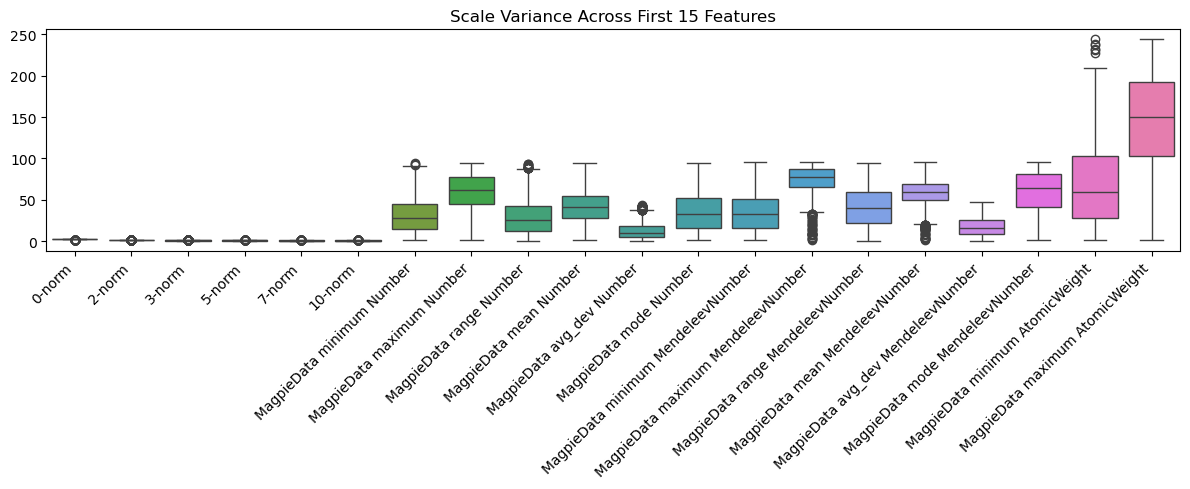

In [22]:
#Visualize scale variances of the features
plt.figure(figsize=(12, 5))
# Plotting the first 15 features as a representative sample
sns.boxplot(data=Xdf_clean.iloc[:, :20])
plt.xticks(rotation=45, ha='right')
plt.title("Scale Variance Across First 15 Features")
plt.tight_layout()
plt.show()

As seen above, that scale of these features vary drastically, the standard deviations range from ~0.059 to ~841.<br>
A feature with standard deviation 841 will completely dominate a feature with standard deviation 0.059 when I fit a Regression model.<br>
This dataset absolutely requires scaling before fitting any regression model.

## Split the data into train, valation and test datasets
Since I will be comparing models throughout this project, I will use a valation dataset to evaluate model performance, saving the test dataset for a final model evaluation.<br>
Below I split the dataset into train, val, and test sets.

In [23]:
# Extract raw arrays from DataFrame/Series
y = y_clean
X = Xdf_clean.values

# 60 / 20 / 20 split, and scaling fitted on the training set only
X_train, X_val, X_test, y_train, y_val, y_test = split_and_scale(X, y)

# PyTorch versions of the arrays
X_tr_t = torch.tensor(X_train)
X_val_t = torch.tensor(X_val)

y_tr_t = torch.tensor(y_train).view(-1, 1)
y_val_t = torch.tensor(y_val).view(-1, 1)

train_full_ds = TensorDataset(X_tr_t, y_tr_t)

print(f"Training {len(X_train):,} | validation {len(X_val):,} | test {len(X_test):,}")

Training 3,078 | validation 1,026 | test 1,027


In [24]:
# Count exact number of zeros
zero_count_train = np.count_nonzero(y_train == 0.0)
zero_count_val = np.count_nonzero(y_val == 0.0)

# Calculate the percentage
zero_percentage_train = (zero_count_train / y_train.size) * 100
zero_percentage_val = (zero_count_val / y_val.size) * 100

print(f"Number of zeros in train set: {zero_count_train}")
print(f"Percentage of zeros in train set: {zero_percentage_train:.2f}%")
print(f"Number of zeros in val set: {zero_count_val}")
print(f"Percentage of zeros in val set: {zero_percentage_val:.2f}%")

Number of zeros in train set: 2417
Percentage of zeros in train set: 78.53%
Number of zeros in val set: 784
Percentage of zeros in val set: 76.41%


## Fit a Linear Regressor Prediction model
First I will fit a linear regressor to predict the band gap from the vector of features.<br>

For this dataset, `RobustScaler` is preferred over `StandardScaler` for a couple reasons:

- **Presence of Heavy Skewness**: 32 of our 141 features exhibit extreme skewness ($> 2$ or $< -2$). `StandardScaler` relies on the mean and standard deviation, which are heavily distorted by these long tails (causing our maximum standard deviation to reach a massive `841`).
- **Mitigating the "Squishing" Effect**: By using the median and Interquartile Range (IQR) instead, `RobustScaler` ignores extreme outliers when centering the data. This prevents the normal, non-outlier feature variance from being compressed into a microscopic numerical range, preserving the natural "contrast" of our features.

Initialize and fit the model with the scaled dataset.

In [25]:
# 1. Initialize and fit the model on scaled training data
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# 2. Predict target values on training and val sets
y_train_pred = linear_model.predict(X_train)
y_val_pred = linear_model.predict(X_val)

# 3. Compute evaluation metrics
train_r2 = r2_score(y_train, y_train_pred)
val_r2 = r2_score(y_val, y_val_pred)
val_mse = mean_squared_error(y_val, y_val_pred)
val_mae = mean_absolute_error(y_val, y_val_pred)

print(f"Train R²:  {train_r2:.4f}")
print(f"Val R²:   {val_r2:.4f}")
print(f"Val MSE: {val_mse:.4f}")
print(f"Val MAE:  {val_mae:.4f}")

Train R²:  0.5904
Val R²:   0.5406
Val MSE: 0.5823
Val MAE:  0.4822


Let's visualize the Linear Regression model's predictions vs the actual targets

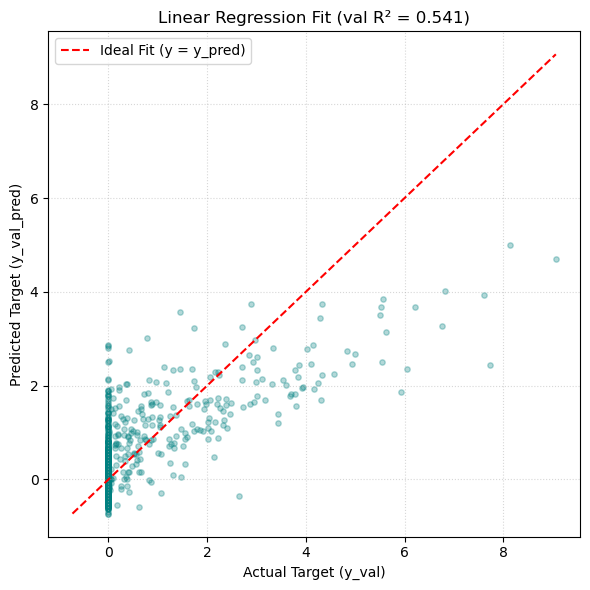

In [26]:
plt.figure(figsize=(6, 6))
plt.scatter(y_val, y_val_pred, alpha=0.3, color='teal', s=15)

# 1:1 reference line
min_val = min(y_val.min(), y_val_pred.min())
max_val = max(y_val.max(), y_val_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal Fit (y = y_pred)')

plt.xlabel("Actual Target (y_val)")
plt.ylabel("Predicted Target (y_val_pred)")
plt.title(f"Linear Regression Fit (val R² = {val_r2:.3f})")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

Let's also visualize the residuals plotted against the true values

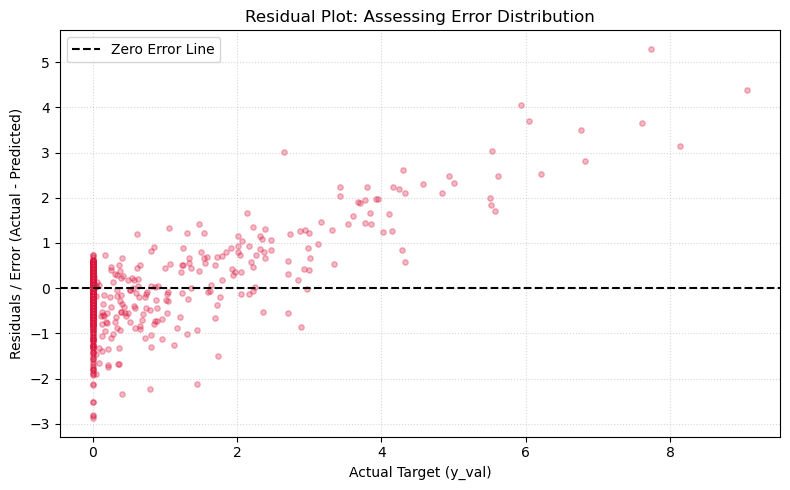

In [27]:
# 1. Calculate the residuals (errors)
residuals = y_val - y_val_pred

plt.figure(figsize=(8, 5))

# 2. Scatter plot of true values vs. the error
plt.scatter(y_val, residuals, alpha=0.3, color='crimson', s=15)

# 3. Reference line at 0 (where error is perfectly zero)
plt.axhline(y=0, color='black', linestyle='--', label='Zero Error Line')

plt.xlabel("Actual Target (y_val)")
plt.ylabel("Residuals / Error (Actual - Predicted)")
plt.title("Residual Plot: Assessing Error Distribution")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

Both plots clearly illustrate the impact of the large population of metallic compounds with a 0.0 eV band gap on our Linear Regression model:

1. **Actual vs. Predicted Plot:** We observe a dense, vertical stack of data points at $X = 0.0$. A linear model cannot inherently capture a flat baseline that suddenly transitions into a positive slope.
2. **Residual Plot:** Beyond the $0.0$ eV cluster, the residuals trend upward as the actual target value increases. This positive slope indicates systematic **underprediction of high band gaps**; because the linear model is heavily anchored by the massive pool of $0.0$ eV metallic data points, it underestimates the magnitude of true wide-band-gap insulators.


**Conclusion:** The non-random, heavily structured distribution of errors confirms that a standard linear model suffers from systematic bias due to the "hurdle" nature of the target variable. To improve performance, we will likely need models capable of handling sharp non-linear thresholds.


## Train a Neural Network
Our baseline Linear Regression model achieved a val $MSE$ of `0.5823` and $R^2$ of `0.5406`. However, diagnostic plots revealed two critical limitations:
1. **The Over-Prediction of Metals:** A rigid linear function cannot flatten completely at $0.0$ eV to represent metallic states while maintaining a slope elsewhere.
2. **The Under-Prediction of Insulators:** The model is heavily pulled down by the 78.53% zero-inflation in the train data, causing it to systematically underestimate wide band gaps (visible as the upward-sloping trend in our residuals).

To capture the complex "hurdle" nature of materials property data, we require a architecture capable of **mapping sharp, non-linear thresholds**. 

A Neural Network is uniquely suited for this task. By incorporating **non-linear activation functions (like ReLU)** across hidden layers, the network acts as a universal function approximator. It can learn to completely deactivate specific pathways (outputting exactly $0.0$ for metal-like features) while simultaneously activating deep pathways to scale up predictions for true wide-band-gap insulators.


### Train a Network with the full dataset
`train_network` builds a network, trains it, and keeps the weights from the epoch with the **lowest valation loss**.<br>
Default patience is 50, model will stop training after 50 epochs without a validation loss decrease.<br>
I can plot the train and loss curves of our MSE loss function using the `h_full` output.

In [28]:
# Train the default model, a 4-layer deep network with 256 hidden units

_, h_full = train_network("Full Network", train_full_ds, X_val_t, y_val_t, features=X_train.shape[1])

Full Network                 best val loss 0.1936 | val MAE 0.1679 eV | val R2 0.8473 at epoch 151 | 201 epochs, 15 s


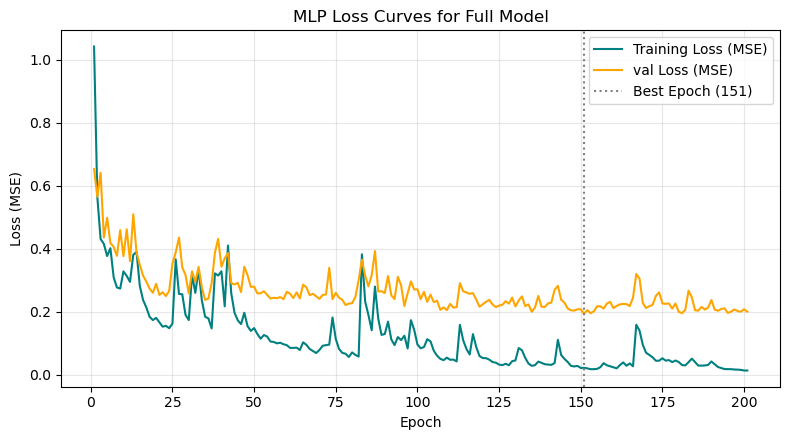

In [29]:
# Plotting the Training vs. valid Loss Curves
epochs_range = range(1, h_full["epochs_run"] + 1)
plt.figure(figsize=(8, 4.5))
plt.plot(epochs_range, h_full["train_loss"], label="Training Loss (MSE)", color="teal")
plt.plot(epochs_range, h_full["val_loss"], label="val Loss (MSE)", color="orange")
plt.axvline(h_full["best_epoch"], color="gray", ls=":", label=f"Best Epoch ({h_full['best_epoch']})")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("MLP Loss Curves for Full Model")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Initial Model Performance comaprison 
The Neural Network significantly outperformed the Linear Regression model.

* **Linear Regression Baseline:** val $R^2 = 0.5406$ | val $\text{MSE} = 0.5823$
* **Neural Network Architecture:** val $R^2 = 0.8473$ | val $\text{MSE} = 0.1936$

## Select the N most important features
141 features is a lot of features to use to train a model, and many of these features could be highly correlated.<br>
It may be possible to train a smaller Neural Network model on only the non-redundant features.<br>
To streamline the dataset down to the $N$ most important features, first filter out highly correlated features followed by a Random Forest Regressor feature selector to select the $N$ most important features. 

#### Rationale for Choosing Random Forest Regressor
Standard linear feature selection methods (e.g., Lasso, ANOVA F-vals) evaluate global trends by drawing straight lines. They heavily struggle with this dataset because it is a "hurdle" problem where over 70% of our targets are exactly 0.0 eV (metals). 
* **Non-Linear Partitions:** A Random Forest relies on decision tree splits, allowing it to easily learn sharp, stepwise non-linear rules (e.g., *“If property X > threshold, isolate these samples and predict 0.0”*).
* **Boundary Definition:** It excels at isolating the exact complex chemical boundaries that separate metals from insulators without requiring manual polynomial feature engineering.

#### The Multicollinearity Concern & Solution (Importance Dilution)
`matminer` chemical descriptors are notoriously redundant and highly correlated (e.g., average vs. maximum atomic mass). 
* **The Concern (Importance Dilution):** When a Random Forest encounters highly correlated features, it randomly selects different versions of the same twin features across its many trees. This splits the error-reduction "credit" between them, artificially diluting their individual importance scores and corrupting our top-$N$ ranking.
* **The Solution:** To ensure our feature selection is structurally stable, we pass the data through a correlation filter first. By dropping redundant features with an absolute Pearson correlation coefficient greater than a threshold (e.g., $|r| > 0.85$), we eliminate twin variables and force the Random Forest to assign the full importance weight to a single, unique representative descriptor.


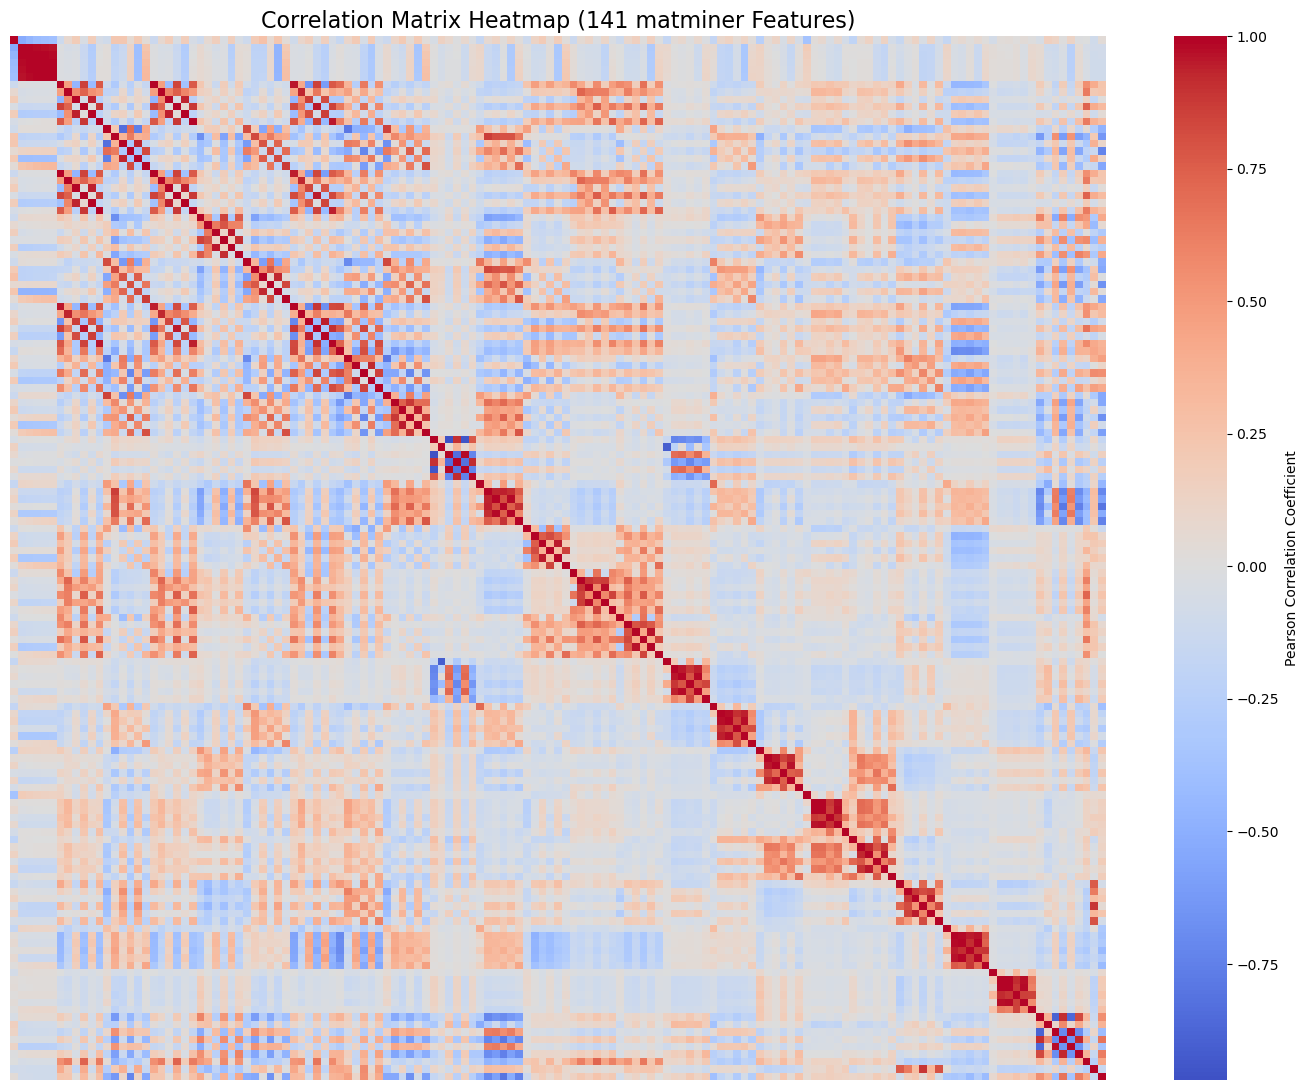

In [30]:
df_features = pd.DataFrame(X_train) 

# Compute the Pearson correlation matrix
corr_matrix = df_features.corr()

# Plot the matrix
plot_corr_mat(corr_matrix)

In [31]:
# Calculate the absolute correlation matrix of your training data
corr_matrix = corr_matrix.abs()

# Select upper triangle of correlation matrix
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Find features with correlation greater than a threshold (e.g., 0.85)
threshold = 0.85
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > threshold)]

# Drop the redundant columns from both sets
X_train_uncorrelated = np.delete(X_train, to_drop, axis=1)
X_val_uncorrelated = np.delete(X_val, to_drop, axis=1)

print(f"Dropped {len(to_drop)} redundant features out of 141 due to high correlation (>0.85).")
print(f"Remaining clean features for Random Forest evaluation: {X_train_uncorrelated.shape[1]}")
print(f"Uncorrelated train dataset shape: {X_train_uncorrelated.shape}")
print(f"Uncorrelated val dataset shape: {X_val_uncorrelated.shape}")

Dropped 73 redundant features out of 141 due to high correlation (>0.85).
Remaining clean features for Random Forest evaluation: 68
Uncorrelated train dataset shape: (3078, 68)
Uncorrelated val dataset shape: (1026, 68)


At a correlation threshold to 0.85, I see that 73 of the 141 features are above this threshold.<br>
Dropping those highly correlated features, I'm left with 68 features to train a new smaller model and evaluate the performance.

### Use Random Forest to further reduce the number of features
To compare the performance of the full and subset networks as N varies, I can further reduce the number of features using random forest regression, train the models, and compare model performance on the valadation data.

In [32]:
# Run Random Forest once on the 67 uncorrelated features to establish a global ranking
rf = RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=-1)
rf.fit(X_train_uncorrelated, y_train)
importances = rf.feature_importances_
sorted_indices = np.argsort(importances)[::-1]

# 2. Build the three distinct feature dictionary configurations
feature_sets = {
    "68 Features (All Uncorrelated)": (X_train_uncorrelated, X_val_uncorrelated),
    "40 Features (Top RF Selected)": (X_train_uncorrelated[:, sorted_indices[:40]], X_val_uncorrelated[:, sorted_indices[:40]]),
    "20 Features (Top RF Selected)": (X_train_uncorrelated[:, sorted_indices[:20]], X_val_uncorrelated[:, sorted_indices[:20]])
}

Create a training set for each of the different feature counts (68,40,20) and train a large and small model with each set.<br>

In [33]:
# Dictionaries to store loss histories for plotting
histories_256x4 = {}
histories_128x2 = {}
final_results = {}
final_results = {}

# Record Full Model baseline if h_full exists
if "h_full" in globals():
    record_metrics(final_results, "141 Features Full Model (256x4)", h_full)

for name, (X_tr, X_va) in feature_sets.items():
    
    # Cast slices into local Torch tensors
    X_tr_t = torch.tensor(X_tr, dtype=torch.float32)
    X_va_t = torch.tensor(X_va, dtype=torch.float32)

    # DataLoader for the training set
    train_ds = TensorDataset(X_tr_t, y_tr_t)

    # Train and record 256x4 network (default) with unique key
    name_large = f"{name} (256x4)"
    print(f"Training {name_large}...")
    _, hist_large = train_network(name_large, train_ds, X_va_t, y_val_t, features=X_tr.shape[1])
    histories_256x4[name] = hist_large
    record_metrics(final_results, name_large, hist_large)

    # Train and record 128x2 network with unique key
    name_small = f"{name} (128x2)"
    print(f"Training {name_small}...")
    _, hist_small = train_network(name_small, train_ds, X_va_t, y_val_t, features=X_tr.shape[1], width=128, depth=2)
    histories_128x2[name] = hist_small
    record_metrics(final_results, name_small, hist_small)

Training 68 Features (All Uncorrelated) (256x4)...
68 Features (All Uncorrelated) (256x4) best val loss 0.2334 | val MAE 0.1936 eV | val R2 0.8159 at epoch  88 | 138 epochs, 10 s
Training 68 Features (All Uncorrelated) (128x2)...
68 Features (All Uncorrelated) (128x2) best val loss 0.2128 | val MAE 0.1946 eV | val R2 0.8321 at epoch 328 | 378 epochs, 11 s
Training 40 Features (Top RF Selected) (256x4)...
40 Features (Top RF Selected) (256x4) best val loss 0.2155 | val MAE 0.1766 eV | val R2 0.8300 at epoch 135 | 185 epochs, 13 s
Training 40 Features (Top RF Selected) (128x2)...
40 Features (Top RF Selected) (128x2) best val loss 0.2056 | val MAE 0.2025 eV | val R2 0.8378 at epoch 242 | 292 epochs, 8 s
Training 20 Features (Top RF Selected) (256x4)...
20 Features (Top RF Selected) (256x4) best val loss 0.2299 | val MAE 0.1809 eV | val R2 0.8186 at epoch 134 | 184 epochs, 13 s
Training 20 Features (Top RF Selected) (128x2)...
20 Features (Top RF Selected) (128x2) best val loss 0.2282 | v

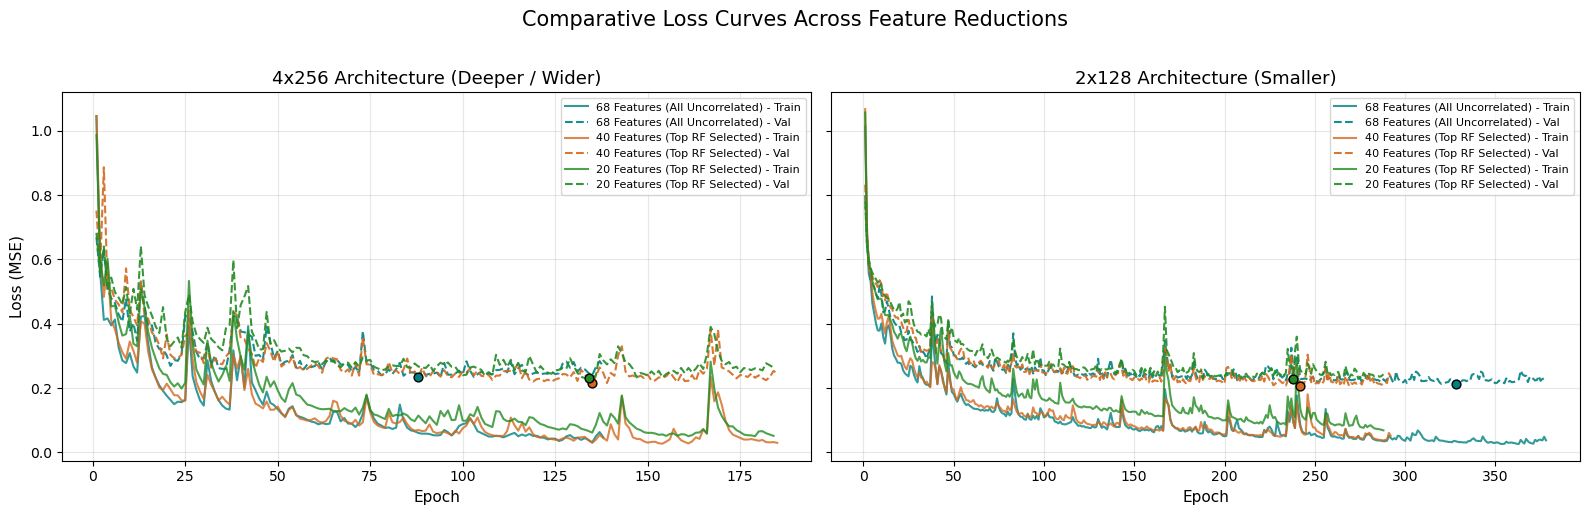

In [34]:
plot_comparative_loss_curves(histories_256x4, histories_128x2)

In [35]:
# Display tabular performance summary
pd.DataFrame({
    name: {
        "best val loss": h["best_val_loss"],
        "best val MAE (eV)": h["best_val_MAE"],
        "best val R2": h["best_val_R2"],
        "best epoch": int(h["Optimal_Epoch"])
    }
    for name, h in final_results.items()
}).T.round(4)

,best val loss,best val MAE (eV),best val R2,best epoch
141 Features Full Model (256x4),0.1936,0.1679,0.8473,151.0
68 Features (All Uncorrelated) (256x4),0.2334,0.1936,0.8159,88.0
68 Features (All Uncorrelated) (128x2),0.2128,0.1946,0.8321,328.0
40 Features (Top RF Selected) (256x4),0.2155,0.1766,0.8300,135.0
40 Features (Top RF Selected) (128x2),0.2056,0.2025,0.8378,242.0
20 Features (Top RF Selected) (256x4),0.2299,0.1809,0.8186,134.0
20 Features (Top RF Selected) (128x2),0.2282,0.2172,0.8200,238.0


### Network comparison
When comparing the large (4 hidden layers, 256 nodes/layer) model trained on all the features with large and small (2 hidden layers, 128 nodes/layer) networks trained on a subset of features, I see that the large model trained with all features performs better than the models trained with a subset of features.<br>
As N varies, I see that there is some variability in the reported validation loss/MSE, but the mean absolute error increases as the number of features used to train decreases for the small network.<br>
Overall, although the large model performs the best, the validation loss across all the models is fairly similiar, and they all perform much better than the Linear Regression model.<br>
Based on the superior performance of the full model, I will use the full model moving forward.

## Regularization
Looking at the Loss Curves for the full model, I see the validation loss falls with the training loss, and then plateaus at a point a bit higher than the training loss.<br>
Here I will add some regularization techniques, dropout and weight decay, to see if valid loss can decrease.

### Dropout

`nn.Dropout(p)` switches off a random fraction `p` of the hidden units on every batch during training. The network can't rely on any single unit, so it learns more robust patterns. `model.eval()` turns dropout off when making predictions.

In [36]:
hists_reg = {"No regularization": h_full}
for p in [0.1, 0.2, 0.5]:
    _, hists_reg[f"Dropout {p}"] = train_network(f"Dropout {p}", train_full_ds, X_val_t, y_val_t, features=X_train.shape[1],
                                                 dropout=p)

Dropout 0.1                  best val loss 0.1846 | val MAE 0.1674 eV | val R2 0.8544 at epoch 112 | 162 epochs, 15 s
Dropout 0.2                  best val loss 0.2117 | val MAE 0.1818 eV | val R2 0.8330 at epoch 161 | 211 epochs, 19 s
Dropout 0.5                  best val loss 0.2291 | val MAE 0.2156 eV | val R2 0.8193 at epoch 182 | 232 epochs, 21 s


### Weight decay

Weight decay shrinks every weight a little toward zero at each step, so the network keeps large weights only where they really help. It's the `weight_decay` argument of the optimizer.

With `AdamW`, each step shrinks the weights by a fraction `lr × weight_decay`. At our learning rate of 0.001 and only 60 epochs, small values do almost nothing, so we try large ones:

In [37]:
for wd in [3.0, 5.0, 10.0]:
    _, hists_reg[f"Weight decay {wd}"] = train_network(f"Weight decay {wd}", train_full_ds, X_val_t, y_val_t, features=X_train.shape[1],
                                                       weight_decay=wd)


Weight decay 3.0             best val loss 0.2504 | val MAE 0.1990 eV | val R2 0.8025 at epoch  68 | 118 epochs, 9 s
Weight decay 5.0             best val loss 0.3215 | val MAE 0.2309 eV | val R2 0.7464 at epoch  21 | 71 epochs, 5 s
Weight decay 10.0            best val loss 0.3807 | val MAE 0.2580 eV | val R2 0.6997 at epoch  21 | 71 epochs, 5 s


In [38]:
pd.DataFrame({
    name: {
        "best val loss": h["best_loss"],
        "best val MAE (eV)": h["best_mae"],
        "best val R2": h["best_r2"],
        "best epoch": h["best_epoch"]
    }
    for name, h in hists_reg.items()
}).T.round(4)

,best val loss,best val MAE (eV),best val R2,best epoch
No regularization,0.1936,0.1679,0.8473,151.0
Dropout 0.1,0.1846,0.1674,0.8544,112.0
Dropout 0.2,0.2117,0.1818,0.8330,161.0
Dropout 0.5,0.2291,0.2156,0.8193,182.0
Weight decay 3.0,0.2504,0.1990,0.8025,68.0
Weight decay 5.0,0.3215,0.2309,0.7464,21.0
Weight decay 10.0,0.3807,0.2580,0.6997,21.0


Here we see a dropout of 0.1 slightly decreased the validation loss and the validation mean absolute error.<br>
However, weight decay did not seem to help the model.

## Hyperparameter tuning
Along with regularization techinques, we can adjust hyperparameters such as the learning rate and the batch size to see how they effect model performance.

### Learning rate

The learning rate sets the size of each update step. Too small and training crawls; too large and the steps overshoot.

In [39]:
hists_lr = {}
for lr in [1e-4, 1e-3, 1e-2, 1e-1]:
    _, hists_lr[f"lr = {lr}"] = train_network(f"Learning rate {lr}", train_full_ds, X_val_t, y_val_t, features=X_train.shape[1],
                                              lr=lr)

Learning rate 0.0001         best val loss 0.2140 | val MAE 0.1909 eV | val R2 0.8312 at epoch 251 | 301 epochs, 22 s
Learning rate 0.001          best val loss 0.1936 | val MAE 0.1679 eV | val R2 0.8473 at epoch 151 | 201 epochs, 14 s
Learning rate 0.01           best val loss 0.2175 | val MAE 0.1998 eV | val R2 0.8284 at epoch 176 | 226 epochs, 16 s
Learning rate 0.1            best val loss 0.9997 | val MAE 0.6243 eV | val R2 0.2114 at epoch   4 | 54 epochs, 4 s


## Batch size

The batch size is how many materials go into each update. Small batches give many noisy updates per epoch; large batches give a few smooth ones and run faster per epoch.

In [40]:
hists_batch = {}
for bs in [32, 128, 256, 512]:
    _, hists_batch[f"batch {bs}"] = train_network(f"Batch size {bs}", train_full_ds, X_val_t, y_val_t, features=X_train.shape[1],
                                                  batch_size=bs)

Batch size 32                best val loss 0.1983 | val MAE 0.1726 eV | val R2 0.8435 at epoch  46 | 96 epochs, 30 s
Batch size 128               best val loss 0.2102 | val MAE 0.1939 eV | val R2 0.8342 at epoch  76 | 126 epochs, 14 s
Batch size 256               best val loss 0.1936 | val MAE 0.1679 eV | val R2 0.8473 at epoch 151 | 201 epochs, 14 s
Batch size 512               best val loss 0.2152 | val MAE 0.1785 eV | val R2 0.8302 at epoch 160 | 210 epochs, 10 s


In [41]:
pd.DataFrame({name: {"updates per epoch": int(np.ceil(len(train_full_ds) / int(name.split()[1]))),
                     "seconds per epoch": h["seconds"] / h["epochs_run"],
                     "val MSE at best": h["best_loss"]}
              for name, h in hists_batch.items()}).T.round(4)

,updates per epoch,seconds per epoch,val MSE at best
batch 32,97.0,0.3126,0.1983
batch 128,25.0,0.1082,0.2102
batch 256,13.0,0.0712,0.1936
batch 512,7.0,0.0483,0.2152


## Putting it together: network against baseline

Taking the best setting from drop-out (0.1), learning rate (1e-3), and batch size (256), I'll train a final model and compare with linear regression on the **test** set, once.

In [42]:
final_model, _ = train_network("Final: dropout 0.1, lr 1e-3, batch 256", train_full_ds, X_val_t, y_val_t, features=X_train.shape[1],
                               dropout=0.1, lr=1e-3, batch_size=256)

final_model.eval()
with torch.no_grad():
    nn_scores = final_model(torch.tensor(X_test)).numpy().ravel()
lin_preds = linear_model.predict(X_test)

# 3. Compute Test RMSE in eV
lin_rmse = np.sqrt(mean_squared_error(y_test, lin_preds))
nn_rmse = np.sqrt(mean_squared_error(y_test, nn_scores))

print(f"Test RMSE, Linear Regression: {lin_rmse:.4f} eV")
print(f"Test RMSE, Neural Network:     {nn_rmse:.4f} eV")

Final: dropout 0.1, lr 1e-3, batch 256 best val loss 0.1846 | val MAE 0.1674 eV | val R2 0.8544 at epoch 112 | 162 epochs, 15 s
Test RMSE, Linear Regression: 0.7190 eV
Test RMSE, Neural Network:     0.4336 eV


## Prepare an ensemble of networks
By training M different networks with thier own random seeds, I can can check the varience between what the M models predict. This represents the model's uncertainty and I would expect that where the model is highly uncertain (large variance), it's prediction error (residual) should be larger.<br>

In [43]:
# Train M=10 ensemble models on full feature set (141 features)
M = 10
seeds = [i * 11 for i in range(M)]

ensemble_models = []
val_predictions = []  # Shape: (M, N_val_samples)

for idx, seed in enumerate(seeds):
    name = f"Ensemble Model {idx + 1}/{M} (Seed: {seed})"
    print(f"Training {name}...")
    
    # Crucial: Pass seed=seed so each model has distinct initial weights and shuffling
    trained_model, _ = train_network(
        name=name, 
        train_ds=train_full_ds, 
        X_val_t=X_val_t, 
        y_val_t=y_val_t, 
        features=X_train.shape[1],
        dropout=0.1, 
        seed=seed
    )
    
    ensemble_models.append(trained_model)
    
    # Extract validation predictions from the best checkpoint of this seed
    trained_model.eval()
    with torch.no_grad():
        preds = trained_model(X_val_t).cpu().numpy().flatten()
    
    val_predictions.append(preds)

# Matrix of predictions across models: shape (10, N_val_samples)
preds_matrix = np.array(val_predictions)

# Compute ensemble mean prediction and standard deviation (uncertainty)
val_ensemble_mean = np.mean(preds_matrix, axis=0)
val_ensemble_std  = np.std(preds_matrix, axis=0)

Training Ensemble Model 1/10 (Seed: 0)...
Ensemble Model 1/10 (Seed: 0) best val loss 0.1846 | val MAE 0.1674 eV | val R2 0.8544 at epoch 112 | 162 epochs, 15 s
Training Ensemble Model 2/10 (Seed: 11)...
Ensemble Model 2/10 (Seed: 11) best val loss 0.1884 | val MAE 0.1711 eV | val R2 0.8514 at epoch 119 | 169 epochs, 15 s
Training Ensemble Model 3/10 (Seed: 22)...
Ensemble Model 3/10 (Seed: 22) best val loss 0.1935 | val MAE 0.1673 eV | val R2 0.8474 at epoch 124 | 174 epochs, 16 s
Training Ensemble Model 4/10 (Seed: 33)...
Ensemble Model 4/10 (Seed: 33) best val loss 0.1912 | val MAE 0.1742 eV | val R2 0.8492 at epoch 138 | 188 epochs, 17 s
Training Ensemble Model 5/10 (Seed: 44)...
Ensemble Model 5/10 (Seed: 44) best val loss 0.1951 | val MAE 0.1748 eV | val R2 0.8461 at epoch 132 | 182 epochs, 16 s
Training Ensemble Model 6/10 (Seed: 55)...
Ensemble Model 6/10 (Seed: 55) best val loss 0.1924 | val MAE 0.1701 eV | val R2 0.8482 at epoch 123 | 173 epochs, 16 s
Training Ensemble Model 

In [44]:
from scipy.stats import spearmanr

val_residuals = np.abs(y_val - val_ensemble_mean)
corr, p_value = spearmanr(val_ensemble_std, val_residuals)

print(f"Spearman Rank Correlation (σ vs. |residual|): {corr:.4f} (p-value: {p_value:.4e})")

Spearman Rank Correlation (σ vs. |residual|): 0.6586 (p-value: 1.3409e-128)


In [45]:
# 1. Collect test predictions across all 10 models
test_predictions = []
X_test_t = torch.tensor(X_test, dtype=torch.float32)

for model in ensemble_models:
    model.eval()
    with torch.no_grad():
        test_preds = model(X_test_t).cpu().numpy().flatten()
    test_predictions.append(test_preds)

test_preds_matrix = np.array(test_predictions)  # Shape: (10, N_test)

# 2. Compute Ensemble Mean and Uncertainty (Std Dev)
y_test_ensemble_mean = np.mean(test_preds_matrix, axis=0)
y_test_ensemble_std  = np.std(test_preds_matrix, axis=0)

# 3. Calculate Final Test Metrics
test_ensemble_rmse = np.sqrt(mean_squared_error(y_test, y_test_ensemble_mean))
test_ensemble_mae  = mean_absolute_error(y_test, y_test_ensemble_mean)
test_ensemble_r2   = r2_score(y_test, y_test_ensemble_mean)

print("=" * 60)
print(f"--- FINAL TEST SET BENCHMARK (M=10 ENSEMBLE) ---")
print(f"Test RMSE: {test_ensemble_rmse:.4f} eV")
print(f"Test MAE:  {test_ensemble_mae:.4f} eV")
print(f"Test R²:   {test_ensemble_r2:.4f}")
print("=" * 60)

--- FINAL TEST SET BENCHMARK (M=10 ENSEMBLE) ---
Test RMSE: 0.4290 eV
Test MAE:  0.1677 eV
Test R²:   0.8253


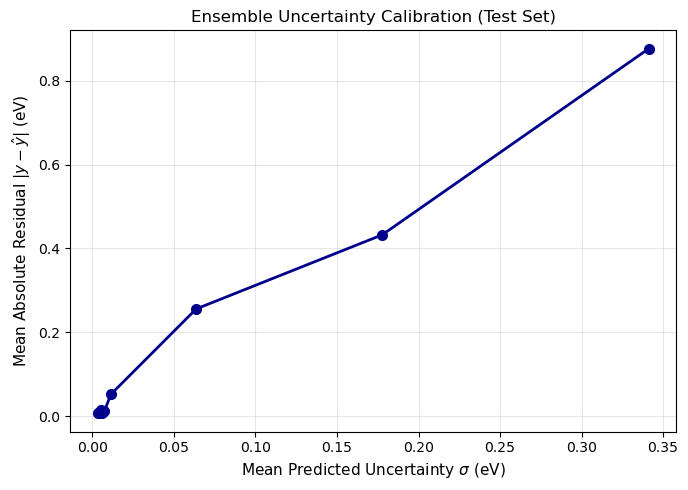

In [46]:
# Bin test predictions into percentiles based on predicted uncertainty (sigma)
n_bins = 10
df_cal = pd.DataFrame({
    'sigma': y_test_ensemble_std,
    'abs_error': np.abs(y_test - y_test_ensemble_mean)
})

df_cal['bin'] = pd.qcut(df_cal['sigma'], q=n_bins, duplicates='drop')
binned = df_cal.groupby('bin', observed=False).mean()

plt.figure(figsize=(7, 5))
plt.plot(binned['sigma'], binned['abs_error'], 'o-', color='darkblue', linewidth=2, markersize=7)
plt.xlabel("Mean Predicted Uncertainty $\sigma$ (eV)", fontsize=11)
plt.ylabel("Mean Absolute Residual $|y - \hat{y}|$ (eV)", fontsize=11)
plt.title("Ensemble Uncertainty Calibration (Test Set)", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()